# Прогноз и демонстрационная нейросеть

Все данные синтетические. Работа выполняется в отдельной ветке; эталон v2 не изменяется.

Найдём корень проекта. В Colab при отсутствии файлов клонируется только рабочая ветка; локально используются уже полученные исходники.

In [1]:
from pathlib import Path
import os, sys
root = Path.cwd()
while root != root.parent and not (root/'efc').exists():
    root = root.parent
if not (root/'efc').exists():
    import subprocess
    target = Path('/content/Forecast_Edge_Fog_Cloud')
    subprocess.run(['git','clone','--branch','night/fefc-v3','https://github.com/annfridreksen/Forecast_Edge_Fog_Cloud.git',str(target)],check=True)
    root=target
os.chdir(root)
sys.path.insert(0,str(root))
print('Рабочая папка:',root)


Рабочая папка: /home/runner/work/Forecast_Edge_Fog_Cloud/Forecast_Edge_Fog_Cloud


Что исследуем: один интерфейс для шести прогнозов. Отдельный синтетический сценарий с четырьмя неравномерно нагруженными Fog не подменяет базовый сценарий парковки.

In [2]:
from efc.forecast.study import forecast_study
from efc.forecast.views import plot_forecasts
from efc.forecast.models import FrozenNetwork,state_of,to_ranks,mm1k
import pandas as pd,json
metrics,predictions,models,sim=forecast_study()
display(metrics)

,method,train_n,calibration_n,test_n,mae_ms,coverage_p95,coverage_before,residual_margin_before_ms,residual_margin_ms,conformal_order_k
0,Naive,2976,904,927,80.184683,0.963323,0.960086,271.100729,275.115720,860
1,MovingAverage,2976,904,927,87.803411,0.905070,0.905070,224.413059,228.095111,860
2,EWMA,2976,904,927,79.898267,0.943905,0.941748,250.890447,252.931800,860
3,QueueingMM1K,2976,904,927,405.990860,0.968716,0.968716,620.528262,643.304611,860
4,Queueing,2976,904,927,47.851562,0.877023,0.877023,105.494344,106.412018,860
5,NeuralNet,2976,904,927,59.647341,0.871629,0.870550,134.450551,134.766956,860


Входы обучения, калибровки и проверки разделены по времени завершения задач. На запрос доступны только ранее завершённые ответы; потерянные события не имеют целевой задержки и считаются отдельно.

In [3]:
meta=json.loads(Path('results/forecast_metadata.json').read_text())
print(meta)
assert meta['train_end_max_s']<meta['cut_train_s']
assert meta['calibration_end_max_s']<meta['cut_test_s']
assert (predictions.last_observed_completion_s<predictions.query_s).all()

{'config': {'n_edge': 80, 'n_fog': 4, 'n_cloud': 8, 'buffer': 50, 'n_tasks': 6000, 'arrival_rate_s': 60, 'mobile_fraction': 0.3, 'edge_fixed_ms': [5.0, 15.0], 'edge_mobile_ms': [8.0, 20.0], 'edge_processing_share': 0.5, 'fog_service_ms': [30.0, 80.0], 'fog_cloud_ms': [20.0, 50.0], 'cloud_service_ms': [10.0, 30.0], 'fog_weights': [4, 2, 1, 1], 'seed': 42}, 'cut_train_s': 61.79136771171639, 'cut_test_s': 82.38851137729432, 'dropped': 1079, 'train_end_max_s': 61.78021912067352, 'calibration_end_max_s': 82.33916734998782, 'notes': 'MLP fit/scaling: train only. Before: empirical higher 95th residual percentile; after: rank ceil((n+1)*.95) of calibration residuals only. Frozen margin before test. Online baselines observe past completions. Queue time series are dependent and shifted: no finite-sample coverage guarantee is claimed; coverage is empirical and conditional on completion.', 'queueing': 'Queueing uses (q+0.5*b+1)*configured mean service plus configured downstream means; QueueingMM1K

Схема показывает заменяемую «розетку». MAE и покрытие p95 — разные показатели: хорошая точечная ошибка не означает правильного хвоста; фактическое недопокрытие не скрывается.

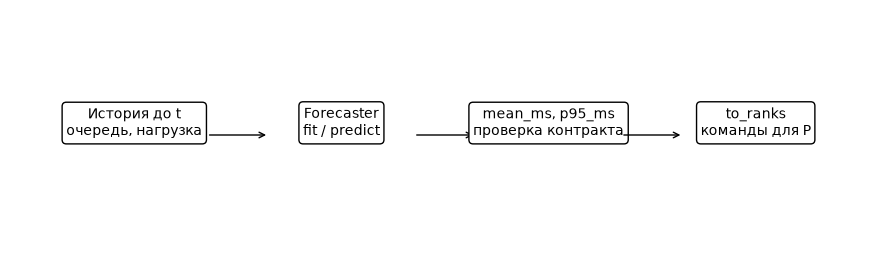

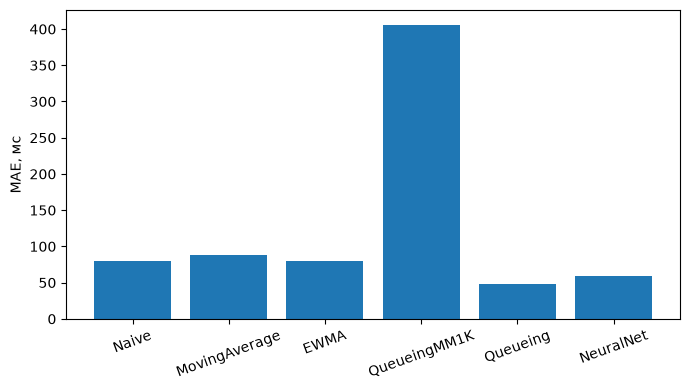

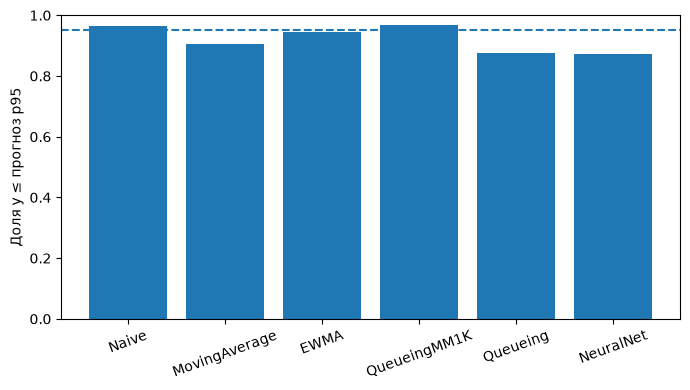

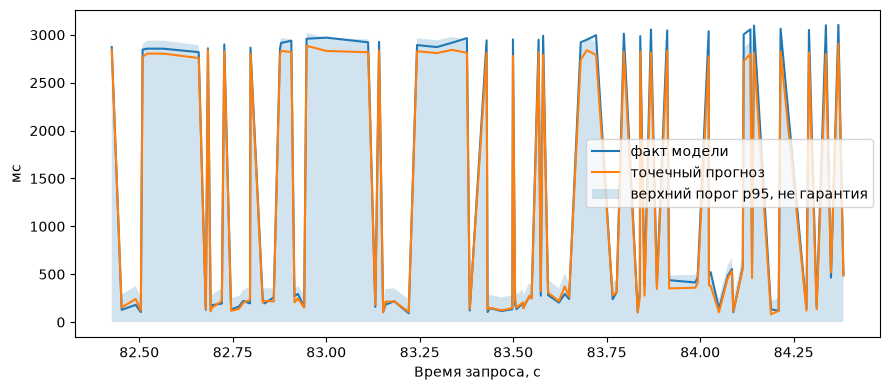

In [4]:
plot_forecasts(metrics,predictions)

Файл my_network.py — пример адаптера для вашей сети. Сохранённые веса демонстрационного MLP проверяем отдельным вычислением без pickle; порядковые команды не подставляются вместо секунд.

In [5]:
frozen=FrozenNetwork(json.loads(Path('results/demo_network.json').read_text()))
s=state_of(next(r for r in sim['tasks'] if r['status']=='completed'))
a=frozen.predict(s);b=models['NeuralNet'].predict(s)
assert abs(a['mean_ms']-b['mean_ms'])<1e-7
print(a)
print('Порядковый пример:',to_ranks({'F0':a,'F1':{'mean_ms':a['mean_ms']+1,'p95_ms':a['p95_ms']+1}}))

{'mean_ms': 50.424962786814376, 'p95_ms': 185.1919191742944}
Порядковый пример: {'F0': 1, 'F1': 2}


Проверка: таблица для статьи читается из того же файла результатов. Queueing учитывает текущую очередь, M/M/1/K сохранён отдельно. Конформная поправка вычислена только по калибровке; зависимость во времени исключает безусловную гарантию95%. M/M/1/K — приближение; равенство Литтла проверяется внутри его предпосылок.

In [6]:
q=mm1k(10,.055,51)
assert abs(q['L']-q['lambda_eff']*q['W_s'])<1e-10
from_file=pd.read_csv('results/forecast_metrics.csv')
assert len(from_file)==6
assert ((from_file.coverage_p95>=0)&(from_file.coverage_p95<=1)).all()
display(from_file[['method','mae_ms','coverage_before','coverage_p95']].rename(columns={'mae_ms':'MAE в статье = модели','coverage_p95':'покрытие в статье = модели'}))
print('OK')

,method,MAE в статье = модели,coverage_before,покрытие в статье = модели
0,Naive,80.184683,0.960086,0.963323
1,MovingAverage,87.803411,0.905070,0.905070
2,EWMA,79.898267,0.941748,0.943905
3,QueueingMM1K,405.990860,0.968716,0.968716
4,Queueing,47.851562,0.877023,0.877023
5,NeuralNet,59.647341,0.870550,0.871629


OK
